In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Modelling Exercise 3


# Number of particles and bonds
N = 17
Nb = N - 1


# Dimensionless units Exercise 2h

zeta = 1.0
kBT = 1.0
l0=1

# From <l_i^2> = 3 kBT / K and l0^2 = <l_i^2>
K = 3.0

# Characteristic diffusion time
tau = zeta * l0**2 / kBT

# Integration timestep
dt = 0.01 * tau

# Number of integration steps
M = 100000

print("K =", K)
print("tau =", tau)
print("dt =", dt)

K = 3.0
tau = 1.0
dt = 0.01


In [5]:

# Initial configuration


r = np.zeros((N, 3))

# Fully stretched chain along x
r[:, 0] = np.arange(N)

r_initial = r.copy()
def spring_forces(r, K):
    """
    Calculate Hookean spring forces for all 17 particles.
    """

    N = len(r)
    F = np.zeros_like(r)

    # First particle
    F[0] = K * (r[1] - r[0])

    # Internal particles
    F[1:-1] = K * (r[:-2]+r[2:] - 2 * r[1:-1])

    # Last particle
    F[-1] = K * (r[-2] - r[-1])

    return F


# Reset initial configuration
r = r_initial.copy()

# Random number generator
rng = np.random.default_rng()

# Store quantities needed for exercises 3b, 3d and 3e
energies = []
mean_bond_lengths = []
bond_history = []
r1_history = []
r17_history = []

for step in range(M):

    # Potential spring forces
    F = spring_forces(r, K)

    # Random force
    sigma_R = np.sqrt(2 * zeta * kBT / dt)
    R = rng.normal(0, sigma_R, size=(N, 3))

    # Finite difference update
    r += (dt / zeta) * (F + R)

    # Bond vectors and squared bond lengths
    bonds = r[1:] - r[:-1]
    bond_squared = np.sum(bonds**2, axis=1)
    bond_lengths = np.sqrt(bond_squared)

    # Potential energy
    U = 0.5 * K * np.sum(bond_squared)

    energies.append(U)
    mean_bond_lengths.append(np.mean(bond_lengths))

    # Save every individual bond length
    bond_history.append(bond_lengths.copy())

    # Save terminal particle positions
    r1_history.append(r[0].copy())
    r17_history.append(r[-1].copy())

# Convert lists to arrays
energies = np.array(energies)
mean_bond_lengths = np.array(mean_bond_lengths)
bond_history = np.array(bond_history)
r1_history = np.array(r1_history)
r17_history = np.array(r17_history)

r_final = r.copy()

In [ ]:

# Check final state


final_bonds = r_final[1:] - r_final[:-1]
final_bond_lengths = np.linalg.norm(final_bonds, axis=1)


print("Mean final bond length:", np.mean(final_bond_lengths))
print("Maximum final bond length:", np.max(final_bond_lengths))

print("\nFinal particle positions:")
print(r_final)

Mean final bond length: 0.9316086437000574
Maximum final bond length: 1.616591920422645

Final particle positions:
[[-3.06994533e-01 -2.05362798e+01  1.39494396e+01]
 [-2.61493935e-01 -2.11176532e+01  1.39401138e+01]
 [-6.38013949e-02 -2.14486934e+01  1.33415571e+01]
 [-6.28775587e-01 -2.23993499e+01  1.34548381e+01]
 [-7.07984766e-01 -2.26370126e+01  1.36788786e+01]
 [ 1.23137699e-01 -2.23320381e+01  1.29297917e+01]
 [ 8.59560219e-02 -2.17891900e+01  1.33148549e+01]
 [-6.88430291e-01 -2.16728482e+01  1.42945337e+01]
 [-9.31104004e-01 -2.11381232e+01  1.31216240e+01]
 [-2.71398402e-01 -2.20036968e+01  1.27377027e+01]
 [ 8.96522061e-01 -2.13523194e+01  1.24883065e+01]
 [-2.04022043e-02 -2.25091330e+01  1.31473980e+01]
 [ 8.15384529e-01 -2.28965366e+01  1.28988769e+01]
 [ 1.12389279e+00 -2.34424110e+01  1.31540459e+01]
 [ 1.12645303e+00 -2.33813865e+01  1.28467121e+01]
 [ 2.20546475e+00 -2.38881749e+01  1.24770319e+01]
 [ 1.96965904e+00 -2.35872376e+01  1.22452587e+01]]


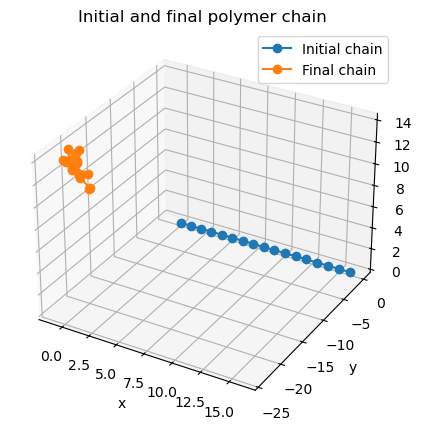

In [33]:
# Plot initial and final chain

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot(r_initial[:, 0], r_initial[:, 1], r_initial[:, 2],"o-", label="Initial chain")

ax.plot(r_final[:, 0], r_final[:, 1], r_final[:, 2],"o-", label="Final chain")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Initial and final polymer chain")
ax.legend()

plt.show()



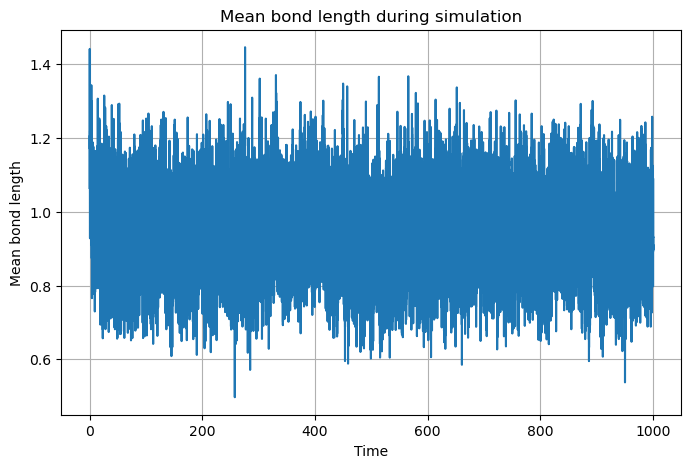

In [8]:
time = np.arange(M) * dt

plt.figure(figsize=(8, 5))

plt.plot(time, mean_bond_lengths)

plt.xlabel("Time")
plt.ylabel("Mean bond length")
plt.title("Mean bond length during simulation")

plt.grid()
plt.show()

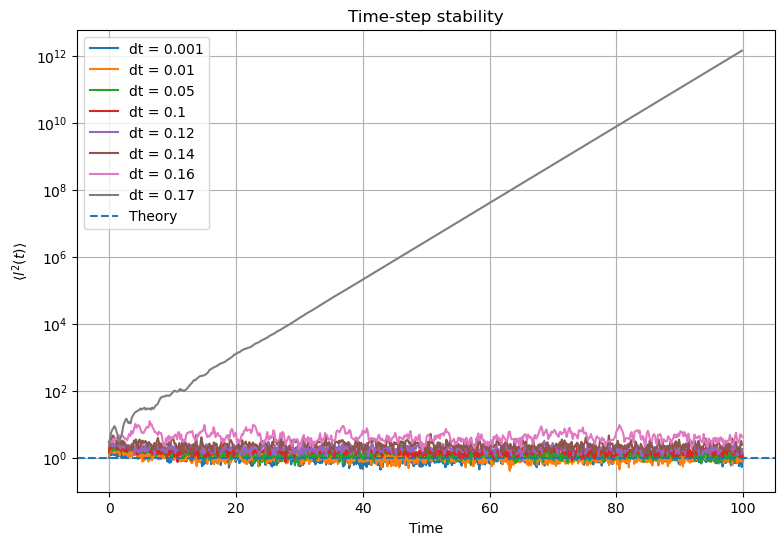

In [17]:
#3c
def run_timestep_test(dt_test, total_time=100):

    M_test = int(total_time / dt_test)

    # Fully stretched initial chain
    r_test = np.zeros((N, 3))
    r_test[:, 0] = np.arange(N)

    rng = np.random.default_rng()

    sigma_R = np.sqrt(2 * zeta * kBT / dt_test)

    mean_l2_history = np.zeros(M_test)

    for step in range(M_test):

        # Spring force
        F = spring_forces(r_test, K)

        # Random force
        R = rng.normal(0, sigma_R, size=(N, 3))

        # Position update
        r_test += (dt_test / zeta) * (F + R)

        # Bond vectors
        bonds = r_test[1:] - r_test[:-1]

        # Mean squared bond length at this time
        mean_l2_history[step] = np.mean(np.sum(bonds**2, axis=1))

    time = np.arange(M_test) * dt_test

    return time, mean_l2_history
dt_values = [0.001, 0.01, 0.05, 0.10, 0.12,0.14,0.16,0.17]

plt.figure(figsize=(9, 6))

for dt_test in dt_values:

    time_test, l2_test = run_timestep_test(dt_test,total_time=100)

    plt.plot(time_test,l2_test,label=f"dt = {dt_test}")

plt.axhline(1.0,linestyle="--",label="Theory")

plt.xlabel("Time")
plt.ylabel(r"$\langle l^2(t)\rangle$")
plt.title("Time-step stability")

plt.yscale("log")

plt.legend()
plt.grid()

plt.show()

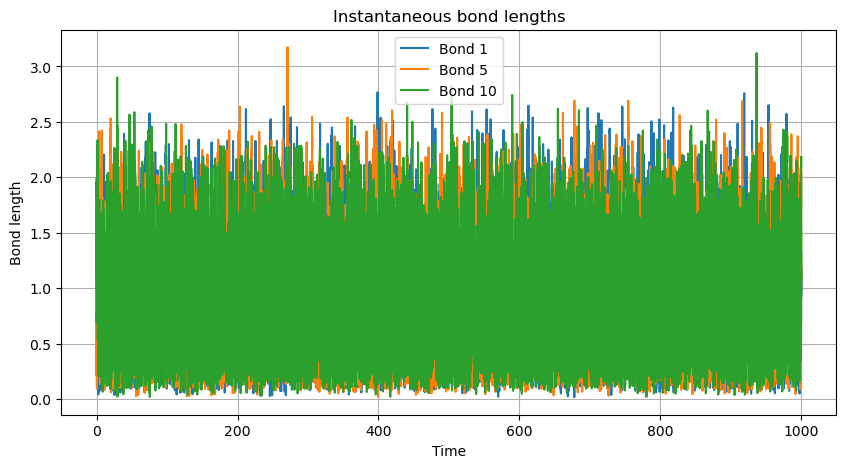

Time-averaged squared length of each bond:
[1.0435685  1.01754547 1.00398967 1.01788559 1.01565634 1.01815001
 1.0420339  1.01593034 1.01845646 1.04123826 1.04432126 1.04231029
 1.03533924 1.02599277 1.03043151 1.02376324]

Average over all bonds = 1.0272883030758517
Theoretical value = 1.0


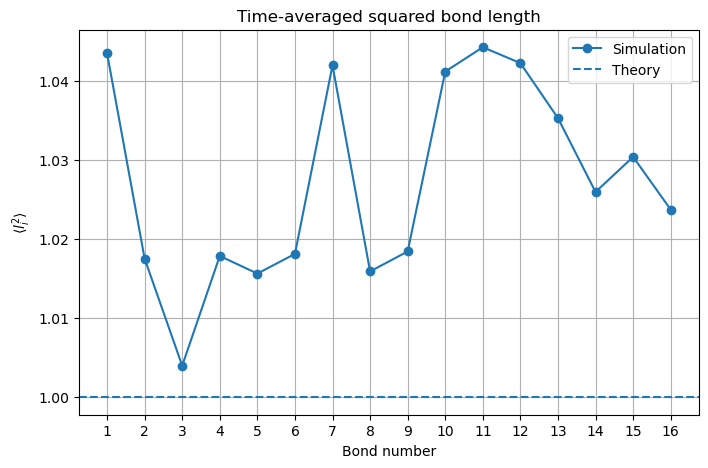

In [ ]:
#3d

import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 17
Nb = N - 1
zeta = 1.0
kBT = 1.0
K = 3.0
dt = 0.01
M = 100000

# Initial stretched chain
r = np.zeros((N, 3))
r[:, 0] = np.arange(N)
r_initial = r.copy()

# Spring forces
def spring_forces(r, K):
    F = np.zeros_like(r)
    F[0] = K * (r[1] - r[0])
    F[1:-1] = K * (r[:-2] + r[2:] - 2 * r[1:-1])
    F[-1] = K * (r[-2] - r[-1])
    return F

# Random number generator
rng = np.random.default_rng()

# Random force standard deviation
sigma_R = np.sqrt(2 * zeta * kBT / dt)

# Store bond lengths
bond_history = np.zeros((M, Nb))

# Simulation
for step in range(M):
    F = spring_forces(r, K)
    R = rng.normal(0, sigma_R, size=(N, 3))
    r += (dt / zeta) * (F + R)
    bonds = r[1:] - r[:-1]
    bond_lengths = np.linalg.norm(bonds, axis=1)
    bond_history[step] = bond_lengths

# Time
time = np.arange(M) * dt

# Plot selected bond lengths
plt.figure(figsize=(10, 5))
plt.plot(time, bond_history[:, 0], label="Bond 1")
plt.plot(time, bond_history[:, 4], label="Bond 5")
plt.plot(time, bond_history[:, 9], label="Bond 10")
plt.xlabel("Time")
plt.ylabel("Bond length")
plt.title("Instantaneous bond lengths")
plt.legend()
plt.grid()
plt.show()


# Squared bond lengths
bond_squared = bond_history**2

# Time average for each bond
mean_l2_each_bond = np.mean(bond_squared, axis=0)

# Average over all bonds
mean_l2_sim = np.mean(mean_l2_each_bond)

# Theoretical value
mean_l2_theory = 3 * kBT / K

# Results
print("Time-averaged squared length of each bond:")
print(mean_l2_each_bond)
print()
print("Average over all bonds =", mean_l2_sim)
print("Theoretical value =", mean_l2_theory)

# Plot time-averaged squared bond length for each bond
bond_numbers = np.arange(1, Nb + 1)

plt.figure(figsize=(8, 5))
plt.plot(bond_numbers, mean_l2_each_bond, "o-", label="Simulation")
plt.axhline(mean_l2_theory, linestyle="--", label="Theory")
plt.xlabel("Bond number")
plt.ylabel(r"$\langle l_i^2 \rangle$")
plt.title("Time-averaged squared bond length")
plt.xticks(bond_numbers)
plt.legend()
plt.grid()
plt.show()

Time-averaged R^2 = 17.574248707809417
Standard deviation of R^2 = 18.339143812333027
Theoretical <R^2> = 16.0


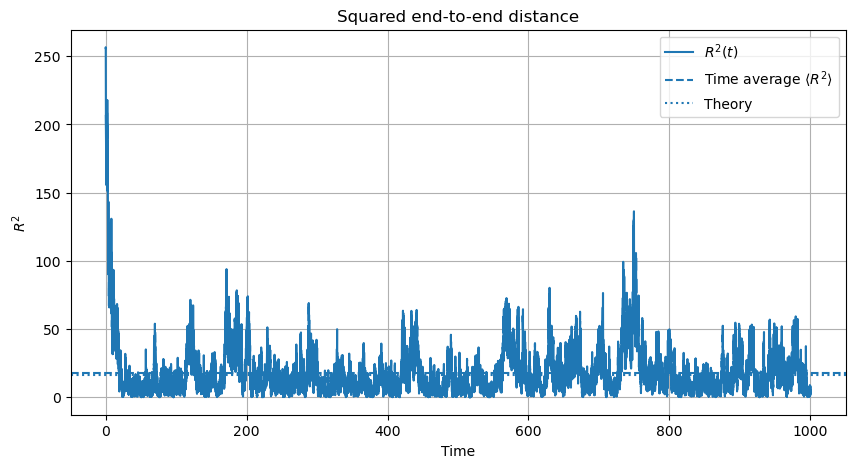

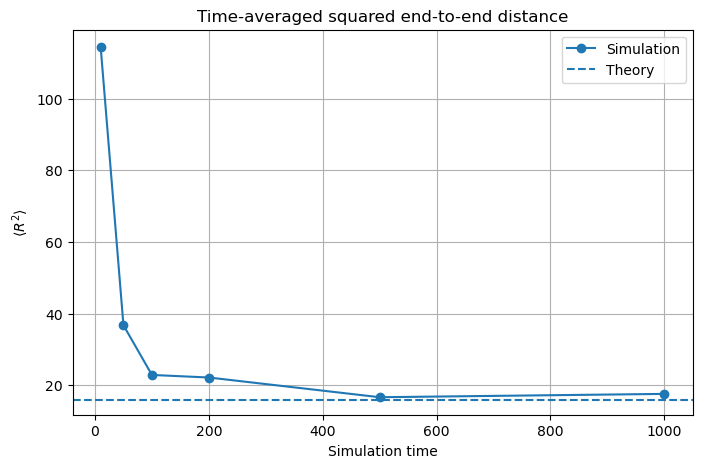

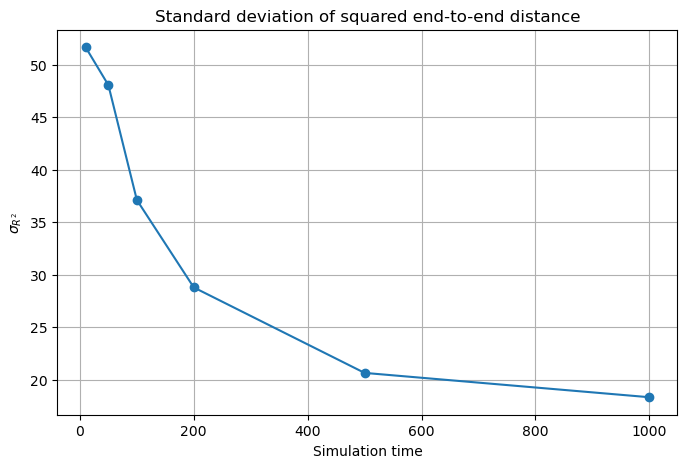

In [31]:
#3e

import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 17
Nb = N - 1
zeta = 1.0
kBT = 1.0
K = 3.0
dt = 0.01
M = 100000

# Initial stretched chain
r = np.zeros((N, 3))
r[:, 0] = np.arange(N)

# Spring forces
def spring_forces(r, K):
    F = np.zeros_like(r)
    F[0] = K * (r[1] - r[0])
    F[1:-1] = K * (r[:-2] + r[2:] - 2 * r[1:-1])
    F[-1] = K * (r[-2] - r[-1])
    return F

# Random number generator
rng = np.random.default_rng()

# Random-force standard deviation
sigma_R = np.sqrt(2 * zeta * kBT / dt)

# Store positions of terminal particles
r1_history = np.zeros((M + 1, 3))
r17_history = np.zeros((M + 1, 3))

# Initial terminal positions
r1_history[0] = r[0]
r17_history[0] = r[-1]

# Brownian-dynamics simulation
for step in range(M):
    F = spring_forces(r, K)
    R = rng.normal(0, sigma_R, size=(N, 3))
    r += (dt / zeta) * (F + R)
    r1_history[step + 1] = r[0]
    r17_history[step + 1] = r[-1]

# Time
time = np.arange(M + 1) * dt

# End-to-end vector
R_end = r17_history - r1_history

# Squared end-to-end distance as a function of time
R2 = np.sum(R_end**2, axis=1)

# Theoretical prediction
mean_l2_theory = 3 * kBT / K
mean_R2_theory = Nb * mean_l2_theory

# Time average and standard deviation over the complete simulation
mean_R2 = np.mean(R2)
std_R2 = np.std(R2, ddof=1)

print("Time-averaged R^2 =", mean_R2)
print("Standard deviation of R^2 =", std_R2)
print("Theoretical <R^2> =", mean_R2_theory)

# Plot R^2 as a function of time
plt.figure(figsize=(10, 5))
plt.plot(time, R2, label=r"$R^2(t)$")
plt.axhline(mean_R2, linestyle="--", label=r"Time average $\langle R^2 \rangle$")
plt.axhline(mean_R2_theory, linestyle=":", label="Theory")
plt.xlabel("Time")
plt.ylabel(r"$R^2$")
plt.title("Squared end-to-end distance")
plt.legend()
plt.grid()
plt.show()

# Different total simulation times
simulation_times = np.array([10, 50, 100, 200, 500, 1000])

# Store time averages and standard deviations
mean_R2_values = np.zeros(len(simulation_times))
std_R2_values = np.zeros(len(simulation_times))

# Calculate statistics for different simulation times using the same trajectory
for i, T in enumerate(simulation_times):
    n = int(T / dt)
    data = R2[:n + 1]
    mean_R2_values[i] = np.mean(data)
    std_R2_values[i] = np.std(data, ddof=1)

# Plot time-averaged R^2 for different simulation times
plt.figure(figsize=(8, 5))
plt.plot(simulation_times, mean_R2_values, "o-", label="Simulation")
plt.axhline(mean_R2_theory, linestyle="--", label="Theory")
plt.xlabel("Simulation time")
plt.ylabel(r"$\langle R^2 \rangle$")
plt.title("Time-averaged squared end-to-end distance")
plt.legend()
plt.grid()
plt.show()

# Plot standard deviation for different simulation times
plt.figure(figsize=(8, 5))
plt.plot(simulation_times, std_R2_values, "o-")
plt.xlabel("Simulation time")
plt.ylabel(r"$\sigma_{R^2}$")
plt.title("Standard deviation of squared end-to-end distance")
plt.grid()
plt.show()